# Lab 8
- **Student Name**: Daniel Alejandro Castillo Martin
- **Student ID**: N10019284
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
---

## 1. Imports and Setup

### 1.1 Imports and Configuration

In [ ]:
# Import the required libraries
import matplotlib.pyplot as plt
import torch

# Import custom modules
from scripts import lab08_starter as S
from src.gan import discriminator_loss, generator_loss_original, generator_loss_non_saturating

# Print the PyTorch version
print(f'PyTorch version: {torch.__version__}')

PyTorch version: 2.15.0+cpu


In [5]:
# Set the seed for reproducibility
DATA_SEED = 0
EXPERIMENT_SEEDS = (0, 1, 2)
N_SAMPLES = 359

In [13]:
# Display the plots inline
%matplotlib inline

### 1.2 Load and Validate the Digits Dataset

Each 8 × 8 grayscale image is flattened into a vector of 64 pixel values. The dataset contains 1,438 training images and 359 test images. The code below displays the image and label shapes and checks the observed pixel ranges against the expected interval of [0, 1].

In [6]:
# Load the task data
Xtr, ytr, Xte, yte = S.load_task(seed = DATA_SEED)

# Print the shape of the training and test images
print(f'Label shapes: train {tuple(ytr.shape)}, test {tuple(yte.shape)}')
print(f'Training pixel range: [{Xtr.min().item():.2f}, {Xtr.max().item():.2f}]')
print(f'Test pixel range: [{Xte.min().item():.2f}, {Xte.max().item():.2f}]')

Label shapes: train (1438,), test (359,)
Training pixel range: [0.00, 1.00]
Test pixel range: [0.00, 1.00]


## 2. GAN

### 2.1 GAN Losses and Numerical Checks

- The discriminator learns to assign high probabilities to real samples and low probabilities to generated samples. Both generator objectives push the discriminator to classify generated samples as real. The non-saturating objective provides a stronger learning signal when the discriminator confidently identifies generated samples as fake.

- All three losses use softplus to compute their values directly from logits for numerical stability. Each implementation is checked against its probability-based formula using the same randomly generated logits. The absolute difference is reported for each loss.

In [7]:
# Generate random logits
rng = torch.Generator().manual_seed(DATA_SEED)
real_logits = torch.randn(128, generator = rng, dtype = torch.float64)
fake_logits = torch.randn(128, generator = rng, dtype = torch.float64)

# Calculate the probabilities
p_real = real_logits.sigmoid()
p_fake = fake_logits.sigmoid()

# Define the checks
checks = {
    'Discriminator': (discriminator_loss(real_logits, fake_logits), -p_real.log().mean() - torch.log1p(-p_fake).mean()),
    'Generator (original)': (generator_loss_original(fake_logits), torch.log1p(-p_fake).mean()),
    'Generator (non-saturating)': (generator_loss_non_saturating(fake_logits), -p_fake.log().mean())
    }

# Print the results
for name, (actual, expected) in checks.items():
    # Calculate the absolute difference
    error = (actual - expected).abs().item()
    status = 'PASS' if error < 1e-12 else 'FAIL'
    print(f'{name}: {status} | absolute difference = {error:.2e}')

Discriminator: PASS | absolute difference = 2.22e-16
Generator (original): PASS | absolute difference = 1.11e-16
Generator (non-saturating): PASS | absolute difference = 0.00e+00


### 2.2 Optimal Discriminator Check

- The discriminator learns to distinguish real samples from a normal distribution with mean 0 and generated samples from one with mean 1.5. Both distributions have a standard deviation of 1.

- With equal numbers of real and generated samples, the optimal probability that a sample is real is its real-data density divided by the sum of the two densities.

- After 3,000 training steps, the learned probabilities are compared with the theoretical probabilities from -2 to 3.5. The largest absolute difference is reported.

In [9]:
# Initialize the discriminator and optimizer
torch.manual_seed(DATA_SEED)
rng = torch.Generator().manual_seed(DATA_SEED)

# Initialize the discriminator and optimizer
discriminator = S.Discriminator(d_in = 1, d_hidden = 32)
optimizer = torch.optim.Adam(discriminator.parameters(), lr = 3e-3)

# Train on fresh batches from the two fixed distributions
for _ in range(3000):
    real_samples = torch.randn(256, 1, generator = rng)
    fake_samples = torch.randn(256, 1, generator = rng) + 1.5

    optimizer.zero_grad()
    loss = discriminator_loss(discriminator(real_samples), discriminator(fake_samples))
    loss.backward()
    optimizer.step()

# Compare the learned and analytical probabilities
x = torch.linspace(-2.0, 3.5, steps = 551)

# Evaluate the discriminator
discriminator.eval()
with torch.no_grad():
    learned_prob = discriminator(x.unsqueeze(1)).sigmoid()

# Calculate the real and fake densities
real_density = torch.exp(-0.5 * x.square())
fake_density = torch.exp(-0.5 * (x - 1.5).square())
optimal_prob = real_density / (real_density + fake_density)

# Calculate the maximum absolute difference
max_gap = (learned_prob - optimal_prob).abs().max().item()
print(f'Maximum absolute difference: {max_gap:.6f}')

Maximum absolute difference: 0.026696


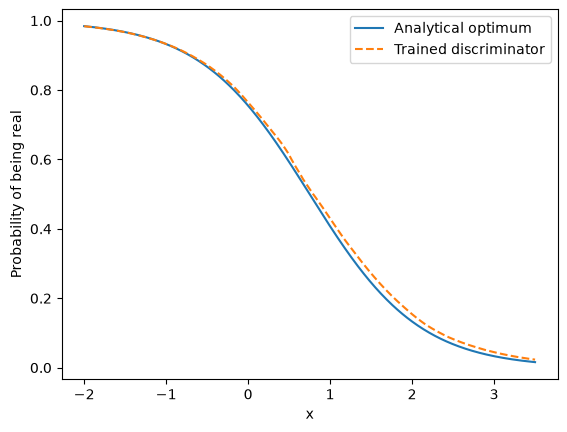

In [ ]:
# Plot the results
plt.plot(x, optimal_prob, label = 'Analytical optimum')
plt.plot(x, learned_prob, '--', label = 'Trained discriminator')
plt.xlabel('x')
plt.ylabel('Probability of being real')
plt.legend()

### 2.3 Generator Gradient Saturation

- The generator's output bias is shifted by 6 in both coordinates, placing its samples far from the real ring data. The discriminator is then trained for 300 steps while the generator stays fixed.

- After training, both generator losses are evaluated on the same batch of generated points. The mean probability that these points are real and the mean gradient norm for each loss are reported. The expected result is a weaker gradient from the original loss when the discriminator confidently identifies the generated points as fake.

In [16]:
# Seed model initialization and batch sampling for reproducibility
torch.manual_seed(DATA_SEED)
rng = torch.Generator().manual_seed(DATA_SEED)

# Generate the real ring data and set the batch and noise dimensions
ring, _ = S.ring_of_gaussians(5000, seed = DATA_SEED)
batch_size = 128
noise_dim = 8

# Initialize the generator and discriminator for two-dimensional points
generator = S.Generator(d_noise = noise_dim, d_out = 2)
discriminator = S.Discriminator(d_in = 2)

# Shift the generator's output by 6 along both coordinates
with torch.no_grad():
    generator.net[-1].bias.add_(6.0)

# Configure Adam to update only the discriminator
optimizer = torch.optim.Adam(discriminator.parameters(), lr = 2e-3, betas = (0.5, 0.9))

# Train the discriminator against the fixed generator for 300 steps
for _ in range(300):
    # Sample a batch of real points and draw input noise
    indices = torch.randint(len(ring), (batch_size,), generator = rng)
    real_points = ring[indices]
    noise = torch.randn(batch_size, noise_dim, generator = rng)

    # Generate fake points without tracking gradients through the generator
    with torch.no_grad():
        fake_points = generator(noise)

    # Clear previous gradients and update the discriminator
    optimizer.zero_grad()
    loss = discriminator_loss(discriminator(real_points), discriminator(fake_points))
    loss.backward()
    optimizer.step()

# Draw a fresh batch of generated points for both gradient measurements
noise = torch.randn(batch_size, noise_dim, generator = rng)
with torch.no_grad():
    fake_points = generator(noise)

# Track gradients with respect to the generated coordinates
fake_points.requires_grad_()
fake_logits = discriminator(fake_points)

# Undo the batch mean and keep the graph for the second gradient calculation
original_grad, = torch.autograd.grad(batch_size * generator_loss_original(fake_logits), fake_points, retain_graph = True)

# Apply the same scaling to the non-saturating loss for a fair comparison
non_saturating_grad, = torch.autograd.grad(batch_size * generator_loss_non_saturating(fake_logits), fake_points,)

# Average the discriminator's real probability over the generated batch
mean_real_probability = fake_logits.detach().sigmoid().mean().item()

# Compute the gradient norm for each point, then average across the batch
original_mean_norm = original_grad.norm(dim = 1).mean().item()
non_saturating_mean_norm = non_saturating_grad.norm(dim = 1).mean().item()

# Report discriminator confidence and the gradient signal from each loss
print(f'Mean D(G(z)): {mean_real_probability:.6e}')
print(f'Original loss mean gradient norm: {original_mean_norm:.6e}')
print(f'Non-saturating loss mean gradient norm: {non_saturating_mean_norm:.6e}')

Mean D(G(z)): 1.587712e-09
Original loss mean gradient norm: 9.257525e-09
Non-saturating loss mean gradient norm: 5.844011e+00


The discriminator assigned the generated points a mean real probability of 1.59e-9. The original loss produced a mean gradient norm of 9.26e-9, compared with 5.84 for the non-saturating loss. In this experiment, the original loss provided almost no learning signal once the discriminator confidently identified the generated points as fake.